# AAI-590 — Data Cleaning and Exploratory Data Analysis
**Project:** Security-Aware AI Intrusion Detection Under Limited Telemetry Visibility in 5G O-RAN  
**Source:** `Lower_Layer_Data.db`, NetsLab-5GORAN-IDD v2, https://zenodo.org/records/18923275  
**Scope:** Radio telemetry only; *not* the 145 GB raw captures or the network-flow dataset.  

This notebook provides a reproducible, commented EDA and a conservative cleaning stage. All figures and statistics are computed from data, not inferred from documentation. It is **not** a training pipeline. No label-dependent imputation, random row splitting, or cross-run generalization claims are made.

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA_PATH = Path('/mnt/data/Lower_Layer_Data.db')
if not DATA_PATH.exists():
    DATA_PATH = Path('Lower_Layer_Data.db')
OUTPUT_DIR = Path('eda_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
assert DATA_PATH.exists(), f'Missing dataset: {DATA_PATH}'
sns.set_theme(style='whitegrid')

## 1. Ingest and inspect
Read-only SQLite access avoids altering the source file. We examine the schema, missing values, duplicates and data types before any transformation.

In [2]:
with sqlite3.connect(f'file:{DATA_PATH.resolve()}?mode=ro', uri=True) as conn:
    tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)
    assert 'lower_layer_data' in tables['name'].tolist()
    raw = pd.read_sql('SELECT * FROM lower_layer_data', conn)
print('Rows and columns:', raw.shape)
print('Types:'); display(raw.dtypes.to_frame('dtype').T)
print('Example records:'); display(raw.head(3))
print('Null counts:'); display(raw.isna().sum().to_frame('nulls').query('nulls > 0'))
print('Fully duplicated records:', int(raw.duplicated().sum()))

Rows and columns: (45244, 25)
Types:


,dlBytes,dlMcs,dlBler,ulBytes,ulMcs,ulBler,ri,phr,pcmax,rsrq,sinr,rsrp,rssi,cqi,pucchSnr,puschSnr,ue_id,timestamp,cellid,in_sync,rnti,pmi,traffic_type,attack_category,attack_subcategory
dtype,int64,int64,float64,int64,int64,float64,int64,int64,int64,float64,float64,int64,float64,int64,float64,float64,float64,float64,float64,float64,object,object,int64,object,object


Example records:


,dlBytes,dlMcs,dlBler,ulBytes,ulMcs,ulBler,ri,phr,pcmax,rsrq,sinr,rsrp,rssi,cqi,pucchSnr,puschSnr,ue_id,timestamp,cellid,in_sync,rnti,pmi,traffic_type,attack_category,attack_subcategory
0,93883433,13,0.0,115160671,9,0.057268,1,15,24,-11.0,14.5,-101,-71.0,15,19.0,33.0,1.0,1.751034e+12,11111111.0,1.0,None,"(0, 0)",1,DoS,DoS_SYN
1,93888597,11,0.0,115199297,10,0.109026,1,11,24,-11.0,15.0,-101,-71.5,15,18.0,19.0,1.0,1.751360e+12,11111111.0,1.0,None,"(0, 0)",1,DoS,DoS_SYN
2,93889971,11,0.0,115202820,9,0.038015,1,11,24,-11.0,16.0,-103,-73.4,15,17.0,35.5,1.0,1.751360e+12,11111111.0,1.0,None,"(0, 0)",1,DoS,DoS_SYN


Null counts:


,nulls
rnti,1540


Fully duplicated records: 0


## 2. Validation and safe cleaning
No removal of physically unusual measurements is justified without expert review. Row-level data can be correlated within runs. `timestamp` is interpreted as Unix milliseconds based on observed magnitude and range, but the original values are retained. The source has no explicit run ID, so no train/test split is attempted.

In [3]:
clean = raw.copy()
# Create a readable UTC timestamp; retain original numerical timestamp for exact auditability.
clean['timestamp_utc'] = pd.to_datetime(clean['timestamp'], unit='ms', utc=True, errors='coerce')
# Note: identifiers, constant columns and labels are intentionally retained in the audit dataset.
# For a *future ML feature matrix*, exclude identifiers, timestamp, and target-derived metadata.
non_feature_cols = ['timestamp', 'timestamp_utc', 'rnti', 'ue_id', 'cellid',
                    'traffic_type', 'attack_category', 'attack_subcategory']
feature_candidates = [c for c in raw.select_dtypes(include='number').columns
                      if c not in non_feature_cols]
# Audit missingness, constant values and basic physical plausibility; flag rather than delete.
missing = clean.isna().sum().sort_values(ascending=False)
constants = [c for c in raw if raw[c].nunique(dropna=True) <= 1]
flags = {
    'invalid_timestamp': int(clean['timestamp_utc'].isna().sum()),
    'negative_dl_bytes': int((clean['dlBytes'] < 0).sum()),
    'negative_ul_bytes': int((clean['ulBytes'] < 0).sum()),
    'dl_bler_outside_0_1': int((~clean['dlBler'].between(0, 1)).sum()),
    'ul_bler_outside_0_1': int((~clean['ulBler'].between(0, 1)).sum()),
    'duplicate_rows': int(clean.duplicated(subset=list(raw.columns)).sum()),
    'duplicate_timestamps': int(clean['timestamp'].duplicated().sum()),
    'globally_sorted_timestamps': bool(clean['timestamp'].is_monotonic_increasing),
}
print('QC flags:', flags)
print('Constant columns:', constants)
print('Missing entries:'); display(missing[missing.gt(0)].to_frame('missing'))
# IMPORTANT: no imputation of rnti: it is an ID with missingness concentrated in DoS.
print('Missing RNTI grouped by label:'); display(clean.assign(missing_rnti=clean.rnti.isna()).groupby('attack_category').missing_rnti.agg(['sum','mean']))
# Sort only for exploratory visualization. This is not a defensible reconstructed run sequence.
chronological = clean.sort_values(['timestamp_utc', 'ue_id'], kind='stable').reset_index(drop=True)
clean.to_csv(OUTPUT_DIR/'radio_telemetry_audited.csv', index=False)

QC flags: {'invalid_timestamp': 0, 'negative_dl_bytes': 0, 'negative_ul_bytes': 0, 'dl_bler_outside_0_1': 0, 'ul_bler_outside_0_1': 0, 'duplicate_rows': 0, 'duplicate_timestamps': 13694, 'globally_sorted_timestamps': False}
Constant columns: ['ri', 'cellid', 'in_sync', 'pmi']
Missing entries:


,missing
rnti,1540


Missing RNTI grouped by label:


,sum,mean
attack_category,,
Benign,0,0.000000
BruteForce,0,0.000000
DDoS,0,0.000000
DoS,1540,0.326202
Probe,0,0.000000
Web Attacks,0,0.000000


## 3. Class and subtype composition
Evaluate imbalance at the record level. Record counts must not be confused with independent experimental-run counts.

Class counts:


,count,pct
attack_category,,
DDoS,15084,33.34
Benign,10664,23.57
Probe,8445,18.67
DoS,4721,10.43
Web Attacks,3273,7.23
BruteForce,3057,6.76


Attack subtypes:


,count
attack_subcategory,
Benign,10664
Probe_OsFingerprinting,6036
DDoS_UDP,4458
DDoS_SYN,3568
DDoS_ICMP,3294
Probe_PortScan,2409
DDoS_ACK,1934
DDoS_Slowloris,1830
BruteForce_SSH,1666


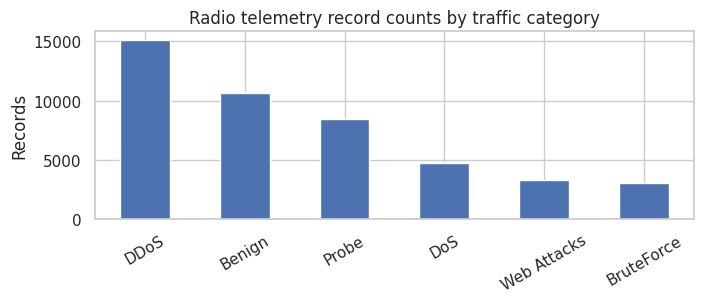

In [4]:
class_counts = clean.attack_category.value_counts()
print('Class counts:'); display(pd.DataFrame({'count':class_counts,'pct':(100*class_counts/len(clean)).round(2)}))
print('Attack subtypes:'); display(clean.attack_subcategory.value_counts().to_frame('count'))
fig, ax = plt.subplots(figsize=(7.2,3.2))
class_counts.plot.bar(ax=ax)
ax.set(title='Radio telemetry record counts by traffic category',xlabel='',ylabel='Records')
ax.tick_params(axis='x',rotation=30)
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'class_distribution.png',dpi=190); plt.show()

## 4. Data completeness and feature variability
Four constant columns offer no within-dataset discriminatory information. They are excluded from **correlation calculations** but retained in the audit copy. An all-record feature comparison can be misleading if attack data were recorded in different sessions or environments.

,count,mean,std,min,5%,25%,50%,75%,95%,max,missing_pct
dlBytes,45244.0,5.281520e+08,1.009603e+09,0.0,2795950.80,2.298549e+07,5.430307e+07,3.123111e+08,2.693785e+09,4.066047e+09,0.0
dlMcs,45244.0,1.320200e+01,5.339000e+00,0.0,6.00,9.000000e+00,1.200000e+01,1.800000e+01,2.200000e+01,2.700000e+01,0.0
dlBler,45244.0,1.640000e-01,2.890000e-01,0.0,0.00,0.000000e+00,4.900000e-02,1.190000e-01,8.830000e-01,9.900000e-01,0.0
ulBytes,45244.0,8.894351e+08,1.551875e+09,0.0,7228624.15,5.522737e+07,1.073774e+08,9.806346e+08,5.057959e+09,5.249338e+09,0.0
ulMcs,45244.0,9.458000e+00,3.494000e+00,0.0,4.00,6.000000e+00,9.000000e+00,1.200000e+01,1.500000e+01,2.000000e+01,0.0
ulBler,45244.0,2.010000e-01,3.340000e-01,0.0,0.00,1.300000e-02,6.500000e-02,1.380000e-01,1.000000e+00,1.000000e+00,0.0
phr,45244.0,1.970300e+01,4.642000e+00,-2.0,13.00,1.700000e+01,1.900000e+01,2.300000e+01,2.800000e+01,3.800000e+01,0.0
pcmax,45244.0,2.078100e+01,1.193100e+01,-29.0,-29.00,2.300000e+01,2.400000e+01,2.400000e+01,2.500000e+01,2.500000e+01,0.0
rsrq,45244.0,-1.090900e+01,6.150000e-01,-32.0,-12.00,-1.100000e+01,-1.100000e+01,-1.050000e+01,-1.050000e+01,-1.050000e+01,0.0
sinr,45244.0,1.640500e+01,5.757000e+00,-10.5,6.50,1.250000e+01,1.650000e+01,2.150000e+01,2.350000e+01,2.350000e+01,0.0


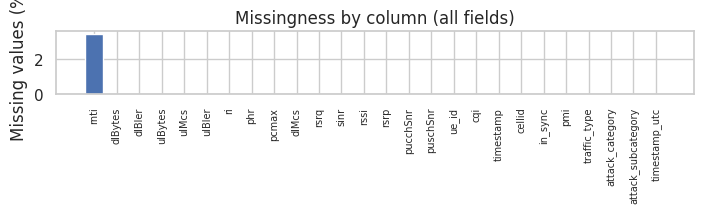

In [5]:
numeric = clean.select_dtypes(include='number')
feature_candidates = [c for c in feature_candidates if numeric[c].nunique(dropna=True)>1]
summary = numeric[feature_candidates].describe(percentiles=[.05,.25,.5,.75,.95]).T
summary['missing_pct'] = 100*numeric[feature_candidates].isna().mean()
summary.to_csv(OUTPUT_DIR/'feature_summary.csv')
display(summary.round(3))
fig,ax=plt.subplots(figsize=(7.2,2.3))
percent_missing=(100*clean.isna().mean()).sort_values(ascending=False)
ax.bar(percent_missing.index,percent_missing.values)
ax.set(ylabel='Missing values (%)',title='Missingness by column (all fields)')
ax.tick_params(axis='x',rotation=90,labelsize=7)
fig.tight_layout();fig.savefig(OUTPUT_DIR/'missingness.png',dpi=190);plt.show()

## 5. Relationships with target: descriptive comparisons
Box plots display variation across recorded labels, not causal attack signatures. Different collection periods or environments may confound apparent differences. Medians are printed for verification.

Group medians:


,sinr,rsrp,cqi,dlBler
attack_category,,,,
Benign,23.5,-94.0,15.0,0.000
BruteForce,23.0,-100.0,15.0,0.050
DDoS,14.5,-103.0,15.0,0.113
DoS,20.0,-100.0,15.0,0.075
Probe,19.0,-100.0,15.0,0.000
Web Attacks,7.0,-102.0,15.0,0.071


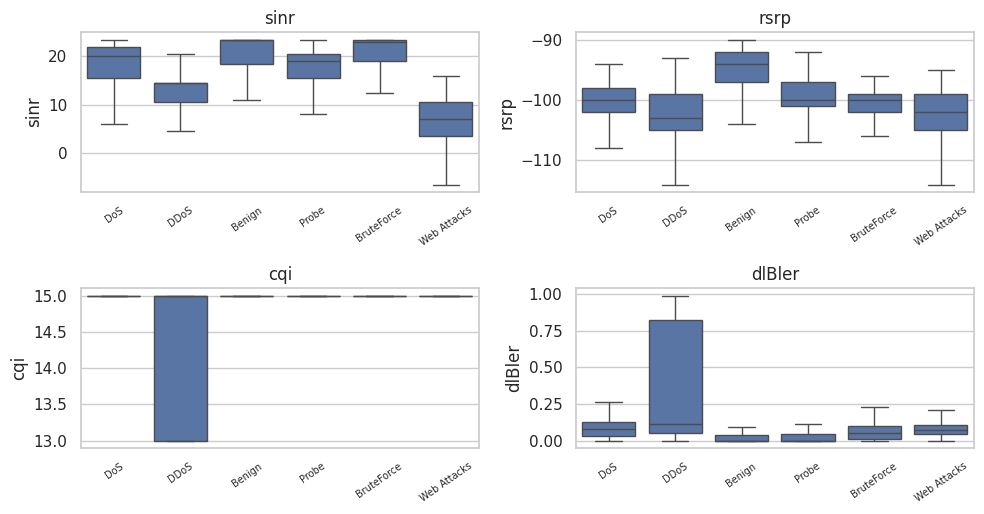

In [6]:
cols=['sinr','rsrp','cqi','dlBler']
print('Group medians:'); display(clean.groupby('attack_category')[cols].median().round(3))
fig, axes = plt.subplots(2,2,figsize=(10,5.3))
for ax,col in zip(axes.flat,cols):
    sns.boxplot(data=clean,x='attack_category',y=col,ax=ax,showfliers=False)
    ax.set(xlabel='',ylabel=col,title=col)
    ax.tick_params(axis='x',labelrotation=35,labelsize=7)
fig.tight_layout();fig.savefig(OUTPUT_DIR/'feature_by_attack.png',dpi=190);plt.show()

## 6. Feature associations and confounding check
Pearson correlations are computed on varying numeric telemetry features. The pooled correlation can be driven by differences between recording sessions or attack categories. Compare within-category associations before interpreting features as interchangeable.

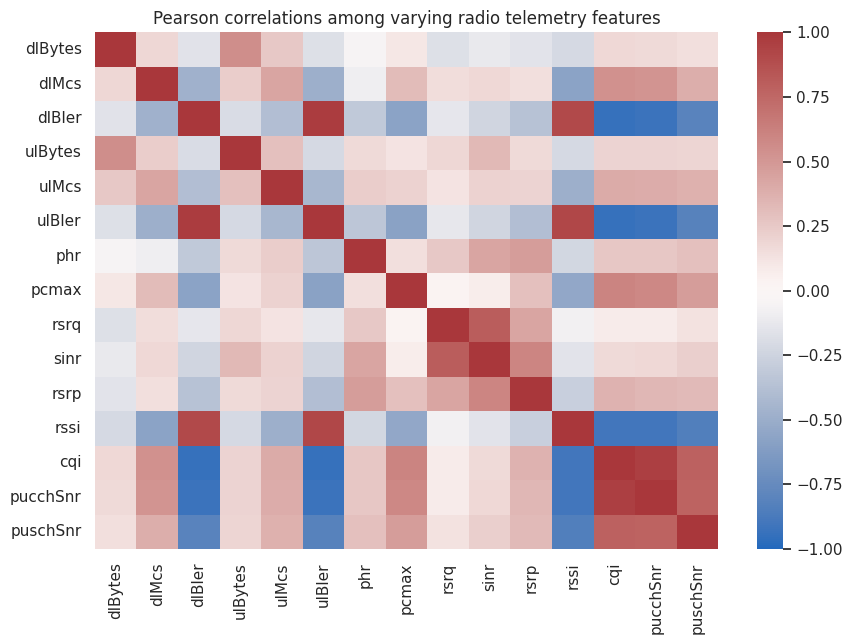

Pooled DL/UL BLER correlation: 0.9719
Within-category DL/UL BLER correlations:
Benign n= 10664 r= 0.9776
BruteForce n= 3057 r= 0.2357
DDoS n= 15084 r= 0.9786
DoS n= 4721 r= 0.9371
Probe n= 8445 r= 0.502
Web Attacks n= 3273 r= 0.2109


In [7]:
corr=clean[feature_candidates].corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(9,6.6))
sns.heatmap(corr, cmap='vlag',center=0,vmin=-1,vmax=1,ax=ax)
ax.set(title='Pearson correlations among varying radio telemetry features')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'feature_correlations.png',dpi=190);plt.show()
print('Pooled DL/UL BLER correlation:',round(clean.dlBler.corr(clean.ulBler),4))
print('Within-category DL/UL BLER correlations:')
for label,group in clean.groupby('attack_category'):
    print(label, 'n=',len(group),'r=',round(group.dlBler.corr(group.ulBler),4))

## 7. Temporal checks, and what cannot be concluded
Multiple records share timestamps; some likely reflect multiple devices or data-merging practices. Global sorting does not recover independent collection runs. Plotting chronologically can help detect recording batches, but not justify a sequence model or run-disjoint evaluation until raw run metadata is available.

Range: 2025-05-09 14:05:06.701000+00:00 through 2025-07-01 13:09:17.835000+00:00
Duplicate timestamp count: 13694
Unique device IDs: 9
Unique days: 8


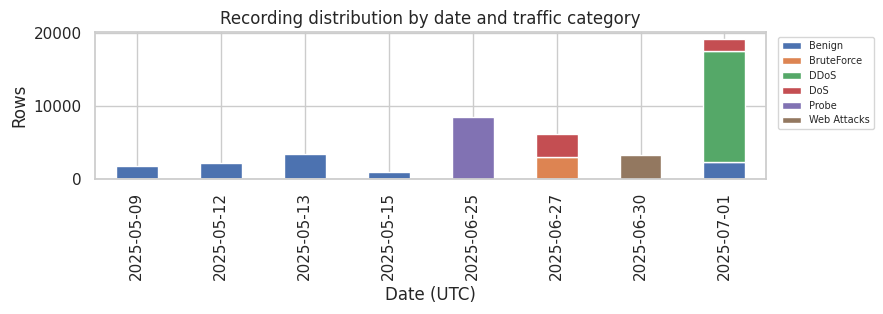

In [8]:
print('Range:',clean.timestamp_utc.min(), 'through',clean.timestamp_utc.max())
print('Duplicate timestamp count:',clean.timestamp.duplicated().sum())
print('Unique device IDs:',clean.ue_id.nunique(dropna=True))
print('Unique days:',clean.timestamp_utc.dt.date.nunique())
by_day=clean.groupby([clean.timestamp_utc.dt.date,'attack_category']).size().unstack(fill_value=0)
ax=by_day.plot.bar(stacked=True,figsize=(9,3.3))
ax.set(xlabel='Date (UTC)',ylabel='Rows',title='Recording distribution by date and traffic category')
ax.legend(loc='upper left',bbox_to_anchor=(1.01,1),fontsize=7)
plt.tight_layout();plt.savefig(OUTPUT_DIR/'records_by_day.png',dpi=190);plt.show()

## 8. Findings, methodological safeguards and future preprocessing
**Observed:** 45,244 records; 25 original columns; 6 traffic categories; no identical complete rows; 1,540 NULL `rnti` entries, all DoS; four constant original columns (`ri`, `cellid`, `in_sync`, `pmi`); non-monotonic global timestamp order. A strong pooled correlation alone is not evidence that two measurements are safely redundant.  

**Cleaning choices:** Preserve all original rows, labels and values; add a validated human-readable timestamp; flag possible violations; omit identifiers/labels/constants only from future model inputs. No row deletion, ID imputation, outlier clipping, or scaling was necessary for the descriptive analysis. Future imputation/scaling must be fitted *only* on training groups.  

**Outstanding data issues:** We lack reliable run/experiment IDs and vendor-specific KPI support evidence. There is only one source/testbed. No cross-vendor interoperability or generalization claim follows from the EDA.  

**Before ML:** recover experiment boundaries and attack-start timestamps from dataset metadata/raw archives; design run-disjoint train/validation/test groups; exclude ID and label-leakage fields; quantify class imbalance per run; generate evidence-grounded telemetry-availability profiles; report family-specific detection and false alarms with uncertainty intervals.  

**Reproduction:** Install pandas, numpy, matplotlib, seaborn, nbformat and jupyter; open this notebook with the supplied DB in the working directory or at `/mnt/data/Lower_Layer_Data.db`. No external network or GPU needed.